# Modelo 2: Etapa da compra em que a pessoa está (LarOuAyê)
**Disciplina:** Artificial Intelligence & Chatbot

**Objetivo:** a partir do texto da dúvida, sugerir a **etapa da jornada** (pesquisa, análise documental, negociação e contrato, escritura, ITBI e tributos, registro). Serve para **encaminhar** a pessoa e sugerir o próximo passo.

É um modelo **diferente** do 1: outro conjunto de dados, outros rótulos e outro algoritmo (Naive Bayes).

> **Origem e limites dos dados (registrar no relatório).** As frases foram **escritas pelo grupo/assistente** como amostras sintéticas
> de perguntas reais sobre compra do primeiro imóvel. **Não houve coleta de usuários.** O conjunto de **teste** foi escrito à parte,
> com redação diferente, e **nunca recebe aumento de dados**. Por serem poucas frases, a acurácia é uma **estimativa otimista**:
> perguntas reais de cidadãos terão mais variação, erros de digitação e gírias.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # permite importar larouaye_ia
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from larouaye_ia import nucleo
pd.set_option('display.max_colwidth', 90)

## 1. Análise exploratória

In [2]:
treino, teste = nucleo.carregar('etapa')
print('treino:', treino.shape, '| teste:', teste.shape)
treino.sample(6, random_state=1)

treino: (361, 2) | teste: (18, 2)


,texto,rotulo
307,"Ola, Quanto tempo o cartorio leva para registrar? obrigado",REGISTRO_IMOVEL
302,Quanto custa o registro? me explica,REGISTRO_IMOVEL
93,"Por favor, Vou ao cartorio de notas amanha",ESCRITURA
132,O vendedor mandou a minuta do contrato,NEGOCIACAO_CONTRATO
175,Comprador e vendedor precisam ir juntos ao cartorio?,ESCRITURA
161,Pode me ajudar? Quero saber se o imovel tem dividas antes de fechar me explica,ANALISE_DOCUMENTAL


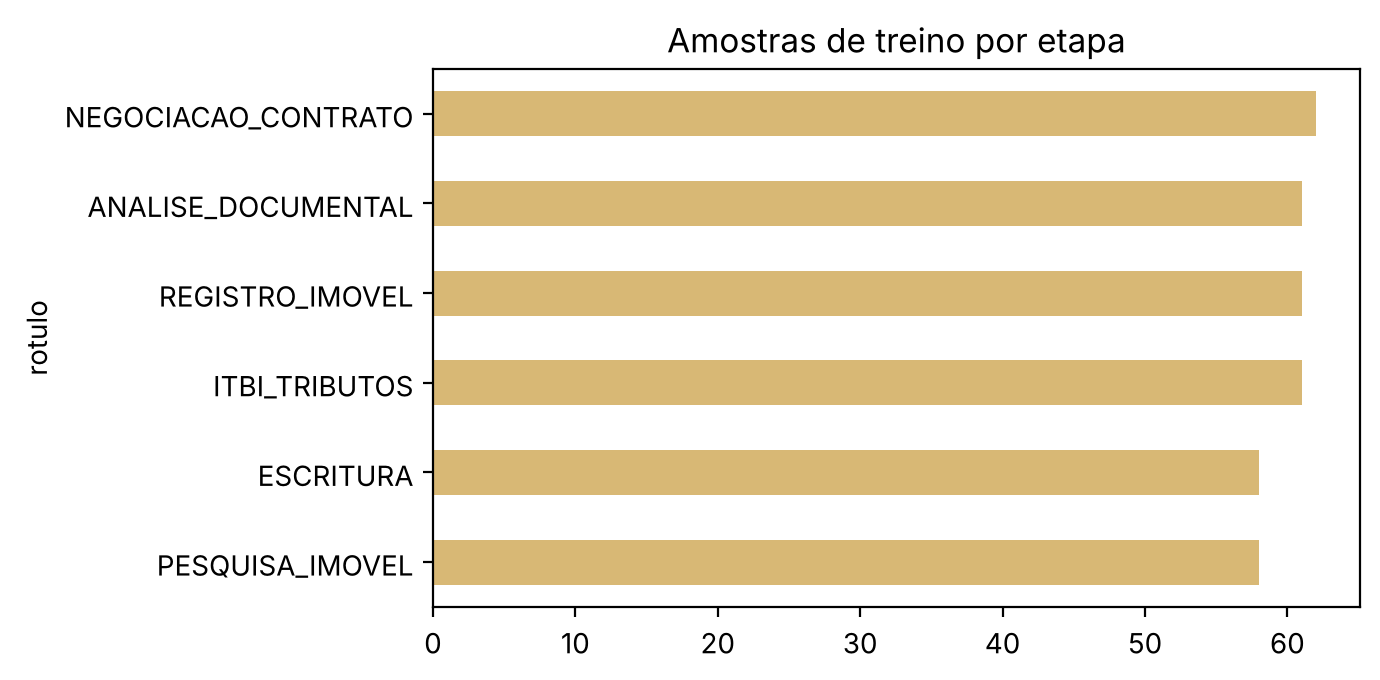

rotulo
NEGOCIACAO_CONTRATO    62
ITBI_TRIBUTOS          61
REGISTRO_IMOVEL        61
ANALISE_DOCUMENTAL     61
ESCRITURA              58
PESQUISA_IMOVEL        58
Name: count, dtype: int64

In [3]:
contagem = treino.rotulo.value_counts()
contagem.sort_values().plot(kind='barh', figsize=(7,3.5), color='#d8b875')
plt.title('Amostras de treino por etapa'); plt.tight_layout(); plt.show()
contagem

## 2. Modelo
- **TF-IDF de palavras (1 e 2 gramas)** sem acentos.
- **Naive Bayes multinomial**: simples, rápido e bom para poucos dados.

In [4]:
pipe = nucleo.pipeline_etapa()
res = nucleo.treinar_e_avaliar('etapa', pipe)
print('Acurácia no TESTE :', res['acuracia_teste'])
print('F1 macro no TESTE:', res['f1_macro_teste'])

Acurácia no TESTE : 0.8889
F1 macro no TESTE: 0.8857


## 3. Avaliação

In [5]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
previsto = pipe.predict(teste.texto)
print(classification_report(teste.rotulo, previsto, zero_division=0))

                     precision    recall  f1-score   support

 ANALISE_DOCUMENTAL       1.00      0.67      0.80         3
          ESCRITURA       1.00      0.67      0.80         3
      ITBI_TRIBUTOS       1.00      1.00      1.00         3
NEGOCIACAO_CONTRATO       1.00      1.00      1.00         3
    PESQUISA_IMOVEL       0.75      1.00      0.86         3
    REGISTRO_IMOVEL       0.75      1.00      0.86         3

           accuracy                           0.89        18
          macro avg       0.92      0.89      0.89        18
       weighted avg       0.92      0.89      0.89        18



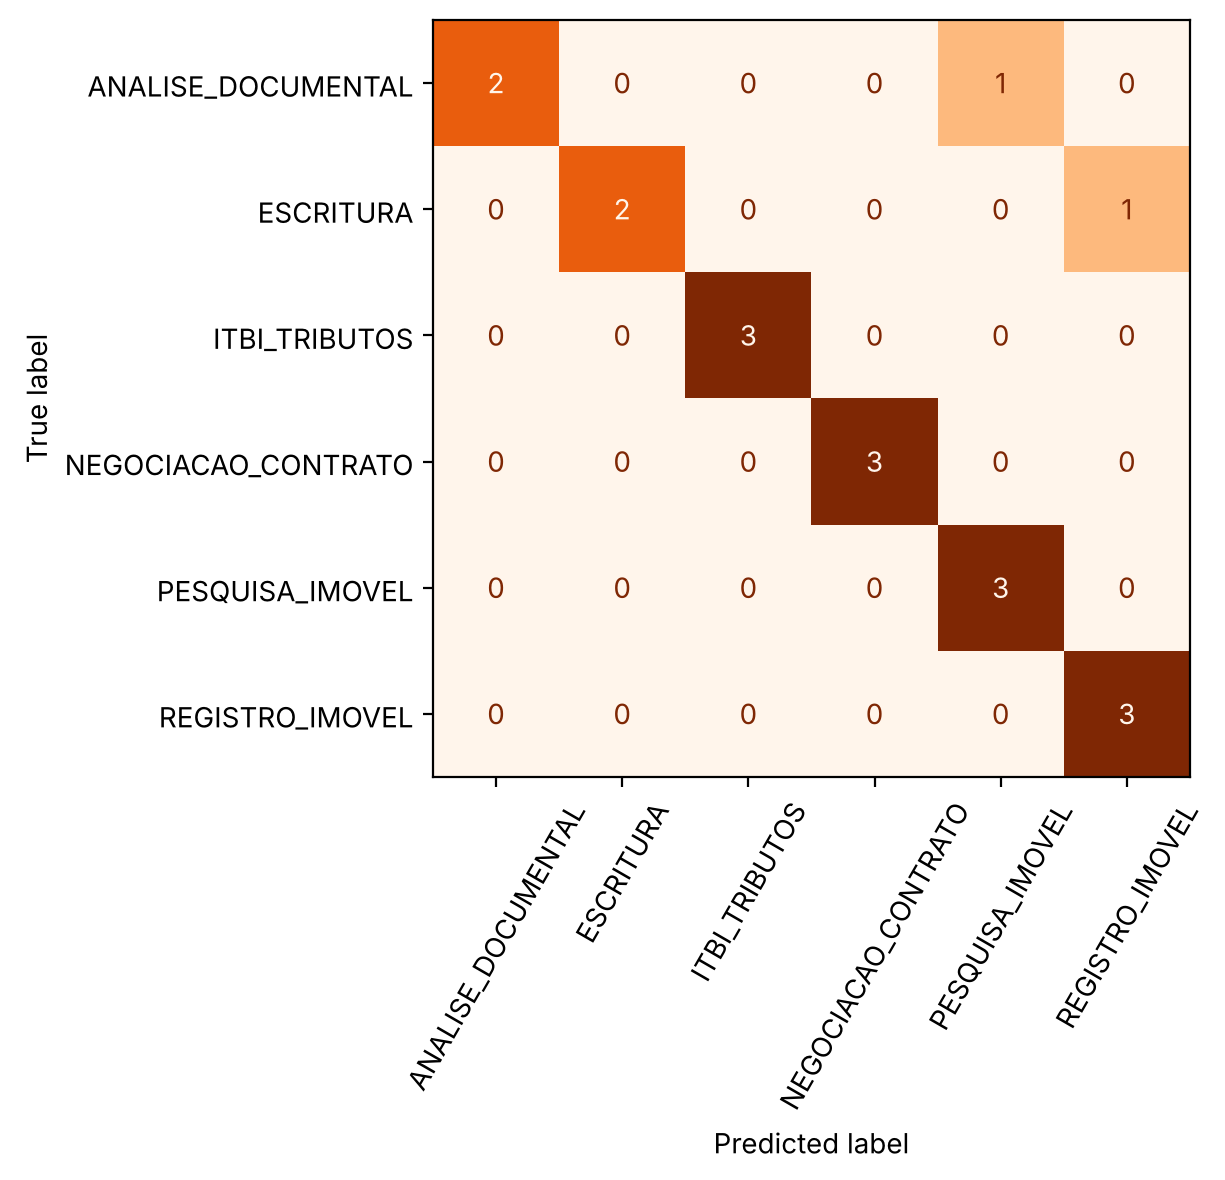

In [6]:
fig, ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay.from_predictions(teste.rotulo, previsto, xticks_rotation=60, cmap='Oranges', ax=ax, colorbar=False)
plt.tight_layout(); plt.show()

In [7]:
teste.assign(previsto=previsto)[teste.rotulo != previsto]

,texto,rotulo,previsto
5,Como verificar se ha dividas na casa que escolhi?,ANALISE_DOCUMENTAL,PESQUISA_IMOVEL
11,Qual o valor para lavrar a escritura no tabelionato?,ESCRITURA,REGISTRO_IMOVEL


## 4. Exemplos

In [8]:
for q in ['Já escolhi o apartamento e vou pedir a matrícula', 'Recebi o contrato do corretor', 'Como pago o ITBI?', 'O cartório devolveu o registro']:
    p = pipe.predict_proba([q])[0]; print(f'{q!r:55} -> {pipe.classes_[p.argmax()]} ({p.max():.2f})')

'Já escolhi o apartamento e vou pedir a matrícula'      -> ANALISE_DOCUMENTAL (0.83)
'Recebi o contrato do corretor'                         -> NEGOCIACAO_CONTRATO (0.86)
'Como pago o ITBI?'                                     -> ITBI_TRIBUTOS (0.82)
'O cartório devolveu o registro'                        -> REGISTRO_IMOVEL (0.77)


## 5. Exportação

In [9]:
caminho = nucleo.exportar(pipe, 'etapa'); print('salvo em', caminho.name)

salvo em modelo_etapa.joblib


## 6. Limitações
- Amostras sintéticas e poucas: a pessoa pode estar em duas etapas ao mesmo tempo.
- A etapa sugerida **não substitui** a etapa escolhida pelo cidadão: o front envia a etapa que ele marcou.
- Perguntas curtas e ambíguas (ex.: *quanto custa?*) tendem a errar a etapa.